In [1]:
import sys
import os
import numpy as np
import pandas as pd

from sklearn.cross_decomposition import PLSCanonical


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_ids = list(range(0, 33+1))
# file_ids = [0,   # minrevs
# 			1,   # minswitch
# 			7,   # maxswitch
# 			11,  # median
# 			12,  # maxrevs
# 			17,  # mean
# 			19,  # paper
# 			21]  # clean
# file_ids = [19]
plot_id = 19

bhl_selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

dims = 3
dims_preca = 5

In [4]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')

# read
(file_ids, filenames,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymographs) = read_utils.get_datas(path, file_ids)

# clear nan values
for i in range(len(file_ids)):
	mask = eigenworms[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	kymographs[i] = kymographs[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# preprocess
pass

In [5]:
plot_idx = file_ids.index(plot_id)

In [6]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_plsc_man, loads_plsc_man_b,
 vars_expl_mans) = train_utils.get_manifolds_plsc(traces,
												  [ds[bhl_selection] for ds in discrete_states],
												  scale=False,
												  n_ls=dims)

In [7]:
save = False

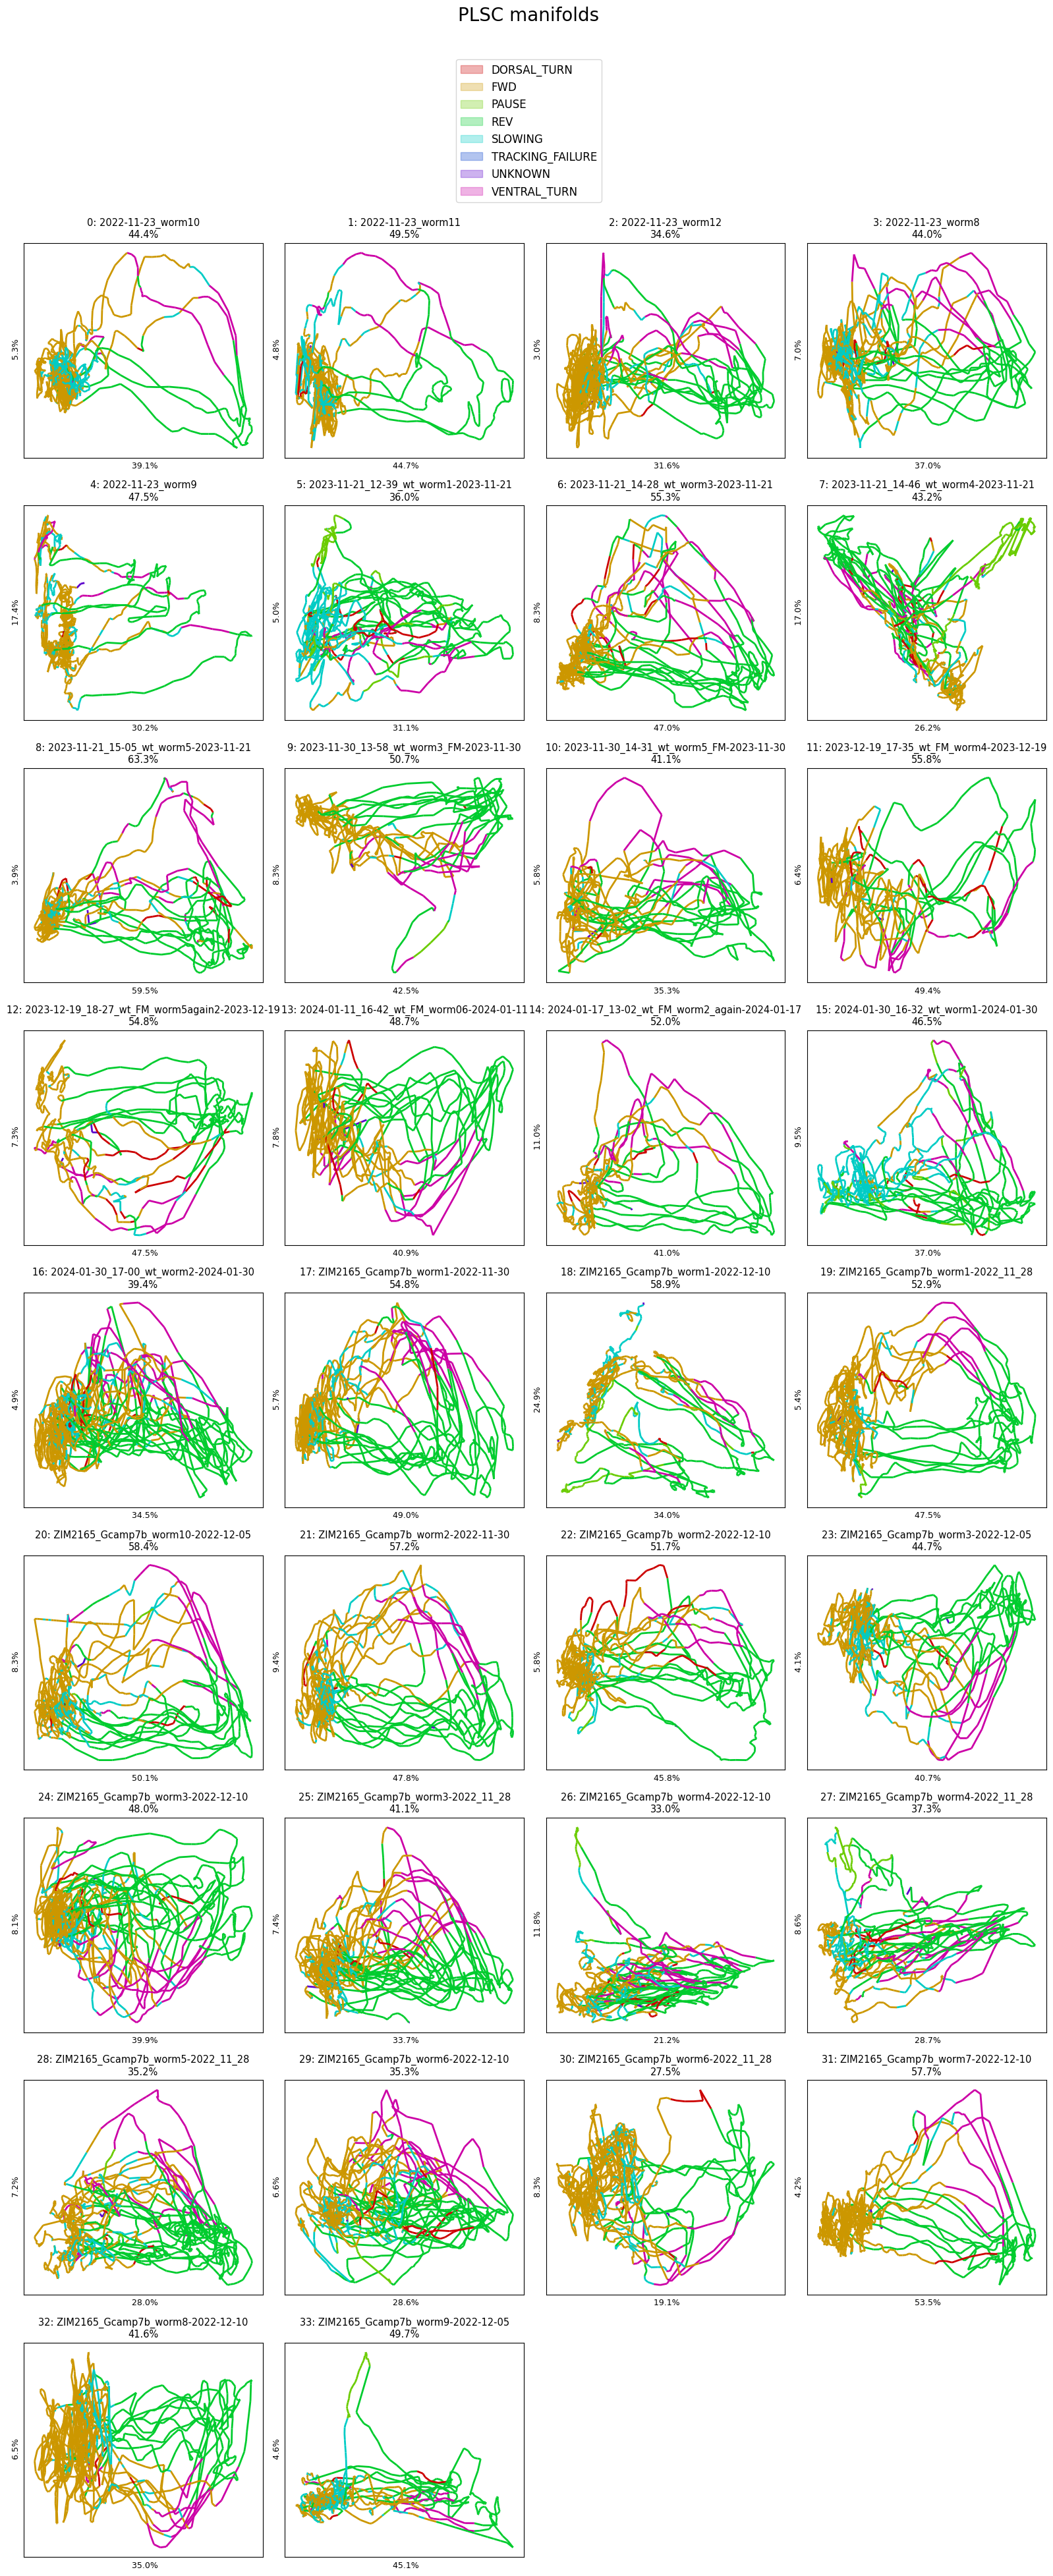

46.8%


In [8]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold,
						  discrete_states,
						  [vx[:2] for vx in vars_expl_mans], None,
						  title='PLSC manifolds', top_space=3.5,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PLSC' if save else None)

In [9]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 							 modes_manifold, discrete_states,
# 							 [vx[:3] for vx in vars_expl_mans], None,
# 							 title='PLSC manifolds', top_space=3.5,
# 							 save_path=f'../../out/plots/manifolds/{dims}-dim-PLSC_3d' if save else None)

In [10]:
# plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 								 modes_manifold, discrete_states,
# 								 [vx[:3] for vx in vars_expl_mans], None,
# 								 titles=['PLSC manifolds'] * len(file_ids), top_space=3.5, animate=True,
# 								 save_path=f'../../out/plots/manifolds/{dims}-dim-PLSC_3d' if save else None)

In [11]:
for i, trace in enumerate(traces):
	print(np.mean(trace.values, axis=0))

[ 1.94448960e-03 -4.24588784e-02  6.67277320e-02  8.78256673e-02
  2.46813957e-04  2.84597426e-02  6.63360293e-02  8.13668150e-02
  5.35337737e-02  4.56792222e-02  7.59198488e-04  5.17630854e-02
 -8.37098721e-03  4.90241554e-03  1.74532111e-02 -4.54646529e-03
 -1.15437628e-02  1.26745513e-02  4.35835897e-02  9.52256200e-03
  2.39365917e-02 -2.63535028e-05  5.59717302e-03  1.06468342e-02
  3.32063964e-03 -5.57329310e-03  8.96279910e-03 -5.75493688e-03
  6.93566900e-05  5.89041307e-04 -5.26006195e-03 -6.78581622e-03
  1.14605384e-02  1.37511852e-02  5.01948260e-03  4.37811604e-03
  5.41855625e-03  6.23213919e-03 -2.15997429e-03  6.86197706e-04
  4.42817804e-03  2.15061856e-02  2.56981105e-02  1.89744332e-02
  4.63643103e-02  8.90341462e-02  9.13867192e-03  3.17494043e-03
 -6.72916856e-03 -7.12747116e-03 -2.46686788e-03  2.27060847e-03
  5.60787813e-03 -9.03836399e-03  5.43218038e-04 -6.23529548e-03
 -4.25740754e-03  8.00070827e-03 -7.83410268e-03  4.03422735e-03
 -2.01786518e-03 -6.24851

In [12]:
traces_residual = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip(traces, recos_manifold)]

for i, trace in enumerate(traces_residual):
	print(np.mean(trace.values, axis=0))

[-6.39360590e-18  1.06560098e-17 -3.72960344e-18 -9.05760836e-18
 -7.99200738e-19  5.32800492e-19 -6.39360590e-18 -2.13120197e-18
 -1.06560098e-18 -2.13120197e-18 -1.59840148e-18 -4.26240393e-18
 -2.66400246e-18  1.59840148e-18  8.52480787e-18 -1.86480172e-18
  0.00000000e+00  1.59840148e-18  6.39360590e-18  1.33200123e-18
 -1.06560098e-18 -5.32800492e-19 -2.13120197e-18  3.99600369e-18
  0.00000000e+00  2.66400246e-19 -2.13120197e-18  1.59840148e-18
 -1.06560098e-18  2.13120197e-18 -5.32800492e-19 -1.59840148e-18
  5.32800492e-19 -1.73160160e-18  1.59840148e-18 -5.32800492e-19
  2.13120197e-18  5.32800492e-19  1.06560098e-18 -1.59840148e-18
 -7.99200738e-19 -5.86080541e-18  4.52880418e-18 -7.99200738e-19
  2.66400246e-18 -2.13120197e-18 -5.32800492e-18 -5.32800492e-19
  5.32800492e-19 -1.86480172e-18 -5.32800492e-19 -1.33200123e-18
  2.13120197e-18  1.06560098e-18 -3.19680295e-18  7.99200738e-19
  0.00000000e+00  0.00000000e+00  5.32800492e-19 -1.59840148e-18
  0.00000000e+00 -3.99600